# Choosing a quantile

A map of means suits a use in which an error above the truth weighs as much as an error below it.
Few uses are like that. An irrigation plan built on predicted soil moisture leaves a crop dry when the
moisture is over-predicted, while an under-prediction wastes only some water. A levee built to a
predicted water level fails when the level is under-predicted, while an over-prediction adds only
concrete. Each use sets its own costs, which
select the reading of the law that serves it. Here we read an ensemble under costs in both
directions, on simulated fields whose truth we know.

## Learning goals

- How a pair of costs, one per unit over and one per unit under, sets the level of the quantile to read.
- How the shape of the loss selects the reading, a quantile, an expectile or the mode.
- How to choose the ensemble by the loss of the use itself.
- How to read the tail beyond a quantile, the value at risk with its expected shortfall.
- Why a block's quantile differs from the mean of its points' quantiles.

*Which value should we report when errors on either side differ in weight?*

## The idea

Let a use charge `over` for each unit by which the reading $\hat z$ exceeds the value $z$ and `under`
for each unit by which it falls short,

$$L(\hat z, z) = \text{over}\,(\hat z - z)^+ + \text{under}\,(z - \hat z)^+ .$$

Over the law of $Z$ at a location, the expected loss is smallest at the quantile of level

$$\alpha = \frac{\text{under}}{\text{over} + \text{under}},$$

so equal costs read the median, an over-prediction five times as costly reads the quantile at 1/6, while
an under-prediction five times as costly reads it at 5/6. The theory Spatialize rests on derives this together with its companions ([The error of an ensemble](https://spatialize.readthedocs.io/en/latest/theory/error.html)). A squared loss with the same costs is minimised by the **expectile** at
$\alpha$, which weighs how far the tail reaches, while a loss charging every error alike is minimised by
the **mode**. For the tail itself, the quantile at a high level is the **value at risk**. The mean
beyond it, the **expected shortfall**, says how large the value is when it exceeds that quantile.

Every one of these is a reading of the law at each location, which the members of an ensemble give.
Spatialize provides them as aggregation functions, `AsymmetricLoss(over, under, kind)`, `Expectile`,
`Percentile` and `ExpectedShortfall`, with the matching cross-validation score
`asymmetric_loss(over, under)`.

## Step by step

### A skewed field

The field is a Voronoi block-mark field on the unit square, 40 cells each with a lognormal value, read
at 300 locations on a 40 × 40 grid. Its skew makes the quantiles spread unevenly about the median, so the
level matters.

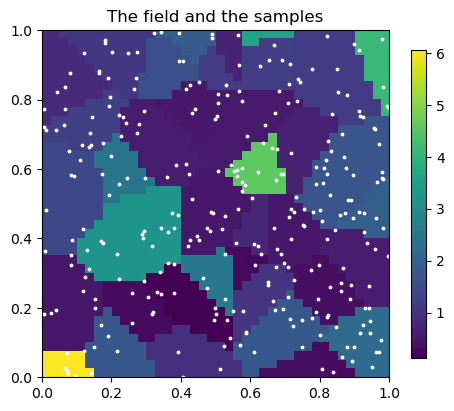

mean 1.38, median 1.10, skewness 1.69


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search
import spatialize.gs.esi.functionals as fn
import spatialize.gs.esi.scoring as sc

spatialize.session.set(empty_cells="coarsen", progress=False)

m = 40
grid = (np.arange(m) + 0.5) / m
xi = np.stack(np.meshgrid(grid, grid), -1).reshape(-1, 2)          # maps are [y, x]

def skewed_field(seed):
    rng = np.random.default_rng(seed)
    nuclei = rng.random((40, 2))
    marks = rng.lognormal(0.0, 0.9, 40)
    value = lambda x: marks[np.argmin(((x[:, None, :] - nuclei[None]) ** 2).sum(-1), axis=1)]
    points = rng.random((300, 2))
    return points, value(points), value(xi)

def realised_loss(reading, truth, over, under, kind="linear"):
    above, below = np.clip(reading - truth, 0, None), np.clip(truth - reading, 0, None)
    if kind == "squared":
        above, below = above ** 2, below ** 2
    return np.mean(over * above + under * below)

points, values, truth = skewed_field(0)
fig, ax = plt.subplots(figsize=(5.6, 5))
im = ax.imshow(truth.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
ax.scatter(points[:, 0], points[:, 1], s=3, c="white")
ax.set_title("The field and the samples")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()
print(f"mean {truth.mean():.2f}, median {np.median(truth):.2f}, skewness {pd.Series(truth).skew():.2f}")

### Choosing the ensemble for the use

Take three uses, over-prediction five times as costly, equal costs and under-prediction five times as
costly. The first reads `AsymmetricLoss(5, 1)`, the quantile at 1/6, the last `AsymmetricLoss(1, 5)`,
the quantile at 5/6. For each use we choose the ensemble among four drawing decoders by
`asymmetric_loss` with its costs, which predicts each datum left out by the use's own reading and
charges the use's loss. We also choose one ensemble by the CRPS, a score of the whole law. Each reading
is then charged its use's loss against the truth.

In [2]:
candidates = (("voronoi", "draw"), ("voronoi", "wdraw_sharpidw"), ("mondrian", "wdraw_sharpidw"), ("mondrian", "wdraw_idw"))
uses = {"over costs 5, under 1": (5.0, 1.0), "equal costs": (1.0, 1.0), "over costs 1, under 5": (1.0, 5.0)}

def choose(scoring):
    best = None
    for p_process, decoder in candidates:
        options = dict(exponent=[2.0]) if decoder == "wdraw_idw" else {}
        knee = esi_pareto_hparams_search(points, values, local_interpolator=decoder, p_process=p_process,
                                         n_partitions=[100], alpha=[0.6, 0.7, 0.8, 0.9, 0.95], k="loo",
                                         scoring=scoring, seed=0, **options).best_result(strategy="knee")
        if best is None or knee["decoder_error"] < best[0]:
            best = (knee["decoder_error"], dict(local_interpolator=decoder, p_process=p_process, alpha=knee["alpha"],
                                                **{key: knee[key] for key in options}))
    return best[1]

run = lambda recipe: esi_nongriddata(points, values, xi, n_partitions=300, seed=0, **recipe).esi_samples()
crps_recipe = choose("crps")
crps_members = run(crps_recipe)
recipes, ensembles, rows = {}, {}, {}
for name, (o, u) in uses.items():
    recipes[name] = choose(sc.asymmetric_loss(over=o, under=u))
    ensembles[name] = run(recipes[name])
    reading = fn.AsymmetricLoss(o, u)
    rows[name] = {"chosen by its loss": f"{recipes[name]['local_interpolator']}, {recipes[name]['p_process']}, alpha {recipes[name]['alpha']}",
                  "loss against the truth": realised_loss(reading(ensembles[name]), truth, o, u),
                  "chosen by the CRPS": f"{crps_recipe['local_interpolator']}, {crps_recipe['p_process']}, alpha {crps_recipe['alpha']}",
                  "loss against the truth, CRPS": realised_loss(reading(crps_members), truth, o, u)}
pd.DataFrame(rows).T

,chosen by its loss,loss against the truth,chosen by the CRPS,"loss against the truth, CRPS"
"over costs 5, under 1","draw, voronoi, alpha 0.9",0.472183,"wdraw_sharpidw, voronoi, alpha 0.9",0.487472
equal costs,"wdraw_sharpidw, mondrian, alpha 0.95",0.243473,"wdraw_sharpidw, voronoi, alpha 0.9",0.246617
"over costs 1, under 5","wdraw_sharpidw, voronoi, alpha 0.8",0.514953,"wdraw_sharpidw, voronoi, alpha 0.9",0.536369


Each use chooses its own ensemble, while the CRPS chooses one for all three, the sharpened weighted
draw on Voronoi partitions at 0.9. Against the truth the choice by the use's loss is the better one
in all three uses, 0.472 against 0.487, 0.243 against 0.247 and 0.515 against 0.536. The use that fears
over-prediction picks the uniform draw, whose members are data with no weighting.

### The loss against the level

For three uses, over-prediction five times as costly, equal costs and under-prediction five times as
costly, we read the quantile of each use's members at 49 levels and charge each map its loss against
the truth. The dotted line marks the level the costs set, the dashed line the loss of the map of means.

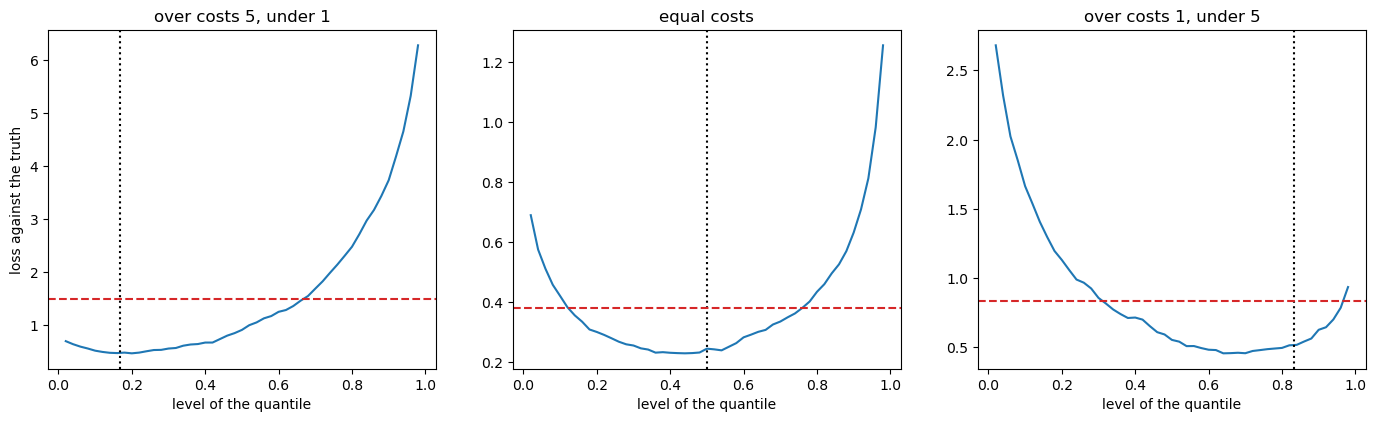

,level the costs set,level at the smallest loss,"loss at the level set, above the smallest","loss of the map of means, above the smallest"
"over costs 5, under 1",0.167,0.20,-0.000,2.180
equal costs,0.500,0.44,0.068,0.670
"over costs 1, under 5",0.833,0.64,0.129,0.822


In [3]:
levels = np.linspace(0.02, 0.98, 49)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
rows = {}
for ax, (name, (o, u)) in zip(axes, uses.items()):
    members = ensembles[name]
    quantile_maps = np.quantile(members, levels, axis=1)                # [level, location]
    curve = np.array([realised_loss(q, truth, o, u) for q in quantile_maps])
    level = u / (o + u)
    at_level = realised_loss(np.quantile(members, level, axis=1), truth, o, u)
    of_mean = realised_loss(members.mean(axis=1), truth, o, u)
    ax.plot(levels, curve, "C0-")
    ax.axvline(level, color="black", ls=":")
    ax.axhline(of_mean, color="C3", ls="--")
    ax.set_xlabel("level of the quantile"); ax.set_title(name)
    rows[name] = {"level the costs set": level, "level at the smallest loss": levels[curve.argmin()],
                  "loss at the level set, above the smallest": at_level / curve.min() - 1,
                  "loss of the map of means, above the smallest": of_mean / curve.min() - 1}
axes[0].set_ylabel("loss against the truth")
plt.show()
pd.DataFrame(rows).T.round(3)

For the costly over-prediction the level 1/6 sits at the bottom of the curve, the smallest loss
falling at 0.20 with the same value. With equal costs the median loses 7 % more than the best level,
0.44. With costly under-prediction the level 5/6 loses 13 % more than the best, 0.64. The curves are flat
near their minimum, so a level a little off loses little, while the map of means loses between 67 % and
218 % more than the best quantile.

### Three shapes of loss

With the costs held at five against one, on that use's members, the shape of the loss changes the reading. The linear loss
reads the quantile at 1/6, the squared loss the expectile at 1/6, the zero-one loss the mode, which
ignores the costs. Each reading is charged both losses against the truth.

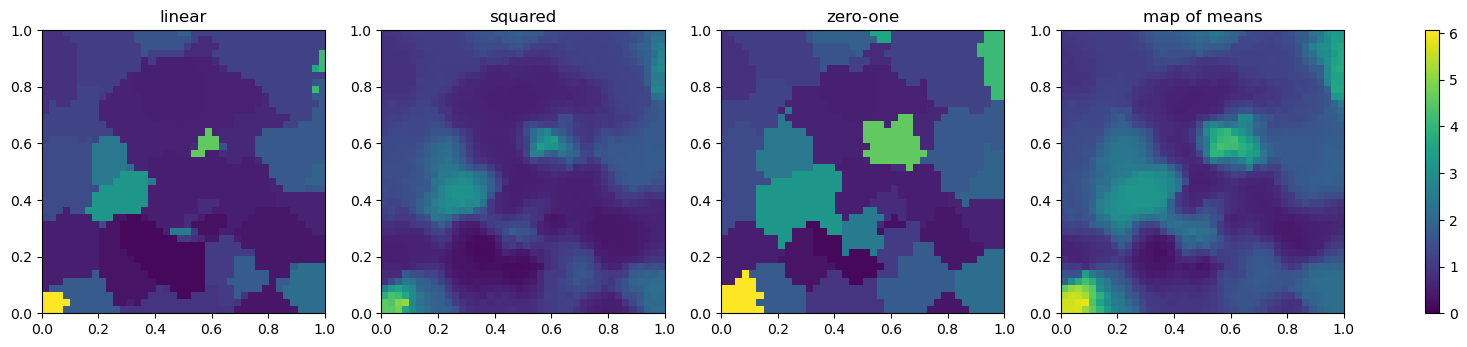

,mean of the reading,"linear loss (5, 1)","squared loss (5, 1)"
linear,1.031,0.472,0.974
squared,1.131,0.821,0.874
zero-one,1.500,0.999,2.831
map of means,1.490,1.502,1.833


In [4]:
over, under = uses["over costs 5, under 1"]
members = ensembles["over costs 5, under 1"]
readings = {kind: fn.AsymmetricLoss(over, under, kind)(members) for kind in ("linear", "squared", "zero-one")}
readings["map of means"] = members.mean(axis=1)
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for ax, (name, z) in zip(axes, readings.items()):
    im = ax.imshow(z.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="viridis", vmin=0, vmax=truth.max())
    ax.set_title(name)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()
pd.DataFrame({name: {"mean of the reading": z.mean(),
                     "linear loss (5, 1)": realised_loss(z, truth, over, under),
                     "squared loss (5, 1)": realised_loss(z, truth, over, under, "squared")}
              for name, z in readings.items()}).T.round(3)

Each reading wins under the loss that selects it. The quantile at 1/6 has the smallest linear loss,
0.472, the expectile the smallest squared loss, 0.874. The mode ignores the costs, its mean of 1.50
close to that of the map of means, losing under both. The quantile map keeps the cells of the
partitions, since a quantile of drawn members is a datum, while the expectile is smooth like the
mean.

### Value at risk with its shortfall

A use that fears high values reads the upper tail, here on the members chosen for the use in which
under-prediction costs more. The value at risk at 0.9 is the members' quantile
at that level, `Percentile(90)`. The expected shortfall, `ExpectedShortfall(0.9)`, is the mean of
the members at or above it. Against the truth, the value should exceed the value at risk at about 10 %
of the locations, and where it does, its mean should come close to the mean expected shortfall there.

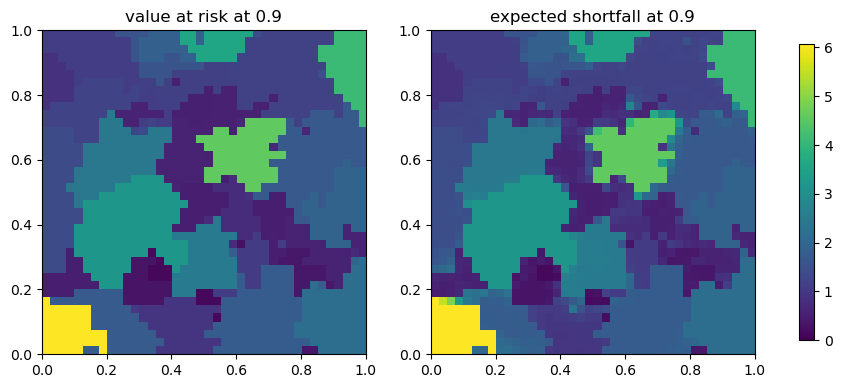

,0
locations above the value at risk,0.334
mean value there,1.857
mean expected shortfall there,1.833
locations where the value at risk equals the shortfall,0.457


In [5]:
members = ensembles["over costs 1, under 5"]
value_at_risk = fn.Percentile(90)(members)
shortfall = fn.ExpectedShortfall(0.9)(members)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
for ax, (title, z) in zip(axes, [("value at risk at 0.9", value_at_risk), ("expected shortfall at 0.9", shortfall)]):
    im = ax.imshow(z.reshape(m, m), origin="lower", extent=(0, 1, 0, 1), cmap="viridis", vmin=0, vmax=truth.max())
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()
beyond = truth > value_at_risk
pd.Series({"locations above the value at risk": beyond.mean(),
           "mean value there": truth[beyond].mean(),
           "mean expected shortfall there": shortfall[beyond].mean(),
           "locations where the value at risk equals the shortfall": np.mean(np.isclose(value_at_risk, shortfall))}).round(3).to_frame()

The value exceeds the value at risk at 33 % of the locations, three times the nominal 10 %. Where it
does, its mean, 1.86, comes close to the mean expected shortfall there, 1.83. At 46 % of the locations
the value at risk equals the shortfall, every member in the upper tenth sharing one datum. The members'
upper tail is too short, the sign of a law too narrow.

### Ten fields

One field could flatter the levels. On ten fields drawn the same way, each use with its recipe chosen
above, we find the level of smallest loss. A randomised PIT, the share of members below the true
value with ties split at random, shows whether the members' law has the right width. A flat histogram
means a law of the right width, a U shape a law too narrow.

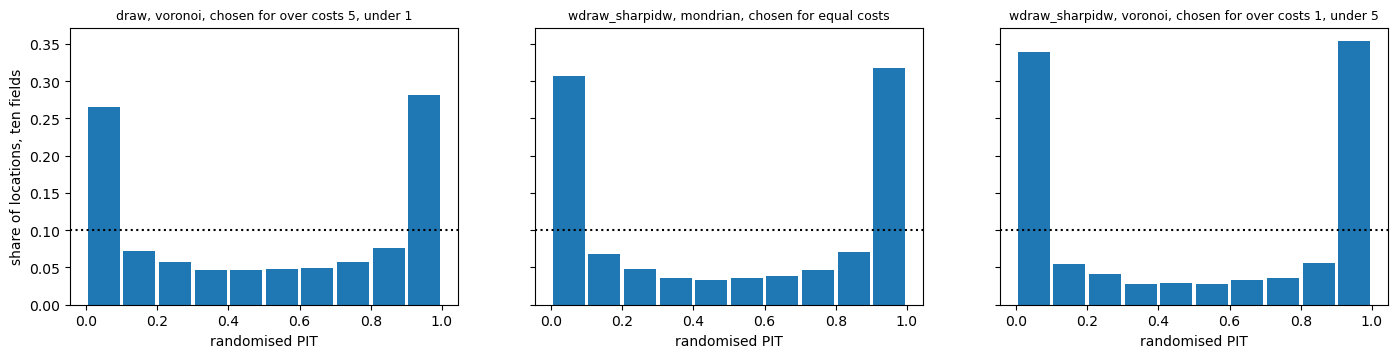

,level the costs set,mean level of smallest loss,lowest,highest
"over costs 5, under 1",0.17,0.28,0.20,0.36
equal costs,0.50,0.49,0.42,0.60
"over costs 1, under 5",0.83,0.79,0.64,0.90


In [6]:
best_levels = {name: [] for name in uses}
pit = {name: [] for name in uses}
for seed in range(10):
    p, v, t = skewed_field(seed)
    for name, (o, u) in uses.items():
        mem = esi_nongriddata(p, v, xi, n_partitions=300, seed=0, **recipes[name]).esi_samples()
        qmaps = np.quantile(mem, levels, axis=1)
        best_levels[name].append(levels[np.argmin([realised_loss(q, t, o, u) for q in qmaps])])
        ties = np.random.default_rng(seed).random(len(t))
        u_values = np.mean(mem < t[:, None], axis=1) + ties * np.mean(mem == t[:, None], axis=1)
        pit[name].append(np.histogram(u_values, bins=10, range=(0, 1))[0] / len(t))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), sharey=True)
for ax, name in zip(axes, uses):
    ax.bar((np.arange(10) + 0.5) / 10, np.mean(pit[name], axis=0), width=0.09, color="C0")
    ax.axhline(0.1, color="black", ls=":")
    ax.set_xlabel("randomised PIT"); ax.set_title(f"{recipes[name]['local_interpolator']}, {recipes[name]['p_process']}, chosen for {name}", fontsize=9)
axes[0].set_ylabel("share of locations, ten fields")
plt.show()
pd.DataFrame({name: {"level the costs set": u / (o + u), "mean level of smallest loss": np.mean(best_levels[name]),
                     "lowest": np.min(best_levels[name]), "highest": np.max(best_levels[name])}
              for name, (o, u) in uses.items()}).T.round(2)

The PIT is U-shaped for all three recipes, with 55 % to 70 % of the locations in the two outer bins
against 20 %. The members' law is too narrow. Its effect on the level of smallest loss is uneven. With
equal costs the level stays at the median on average, 0.49. With costly under-prediction it lies at
0.79 against 0.83, from 0.64 to 0.90 across the fields. With costly over-prediction it lies at 0.28
against 0.17, never below 0.20. The level the costs set is a starting point, close to the best in two
uses out of three.

### A block's quantile

Many decisions act on a whole area at once, a field irrigated as one unit or a district given one
alert. The blocks here are 4 × 4 cells of the grid, 100 of them. The quantile of a block's average is a reading of the law of that average, which each member gives by
averaging over the block. It differs from the mean of the points' quantiles, since a quantile does not
commute with an average. For each asymmetric use, on its members, both are charged its loss against the
true block averages.

In [7]:
side = np.arange(m) // 4
block = (side[None, :] + 10 * side[:, None]).ravel()
true_block = np.array([truth[block == b].mean() for b in range(100)])
rows = {}
for name in ("over costs 5, under 1", "over costs 1, under 5"):
    (o, u), members = uses[name], ensembles[name]
    block_members = np.stack([members[block == b].mean(axis=0) for b in range(100)])
    point_quantile = np.quantile(members, u / (o + u), axis=1)
    lo, hi = np.quantile(block_members, [0.05, 0.95], axis=1)
    plo, phi = np.quantile(members, [0.05, 0.95], axis=1)
    rows[name] = {"loss, quantile of the block average": realised_loss(np.quantile(block_members, u / (o + u), axis=1), true_block, o, u),
                  "loss, mean of the points' quantiles": realised_loss(np.array([point_quantile[block == b].mean() for b in range(100)]), true_block, o, u),
                  "points inside their 5 % to 95 % band": np.mean((plo <= truth) & (truth <= phi)),
                  "blocks inside their 5 % to 95 % band": np.mean((lo <= true_block) & (true_block <= hi))}
pd.DataFrame(rows).T.round(3)

,"loss, quantile of the block average","loss, mean of the points' quantiles",points inside their 5 % to 95 % band,blocks inside their 5 % to 95 % band
"over costs 5, under 1",0.399,0.371,0.573,0.72
"over costs 1, under 5",0.378,0.422,0.422,0.75


The quantile of the block average has the smaller loss for the use that fears under-prediction, 0.378
against 0.422, while the mean of the points' quantiles wins for the other, 0.371 against 0.399. The
block law, an average of members drawn location by location, is too narrow, its band holding 72 % to
75 % of the true blocks against 90 %. Its quantile at 1/6 sits too close to its centre, so it
over-predicts, the costly error of that use. The mean of the points' quantiles lies lower, which happens
to suit that use. The theory favours the quantile of the block average, provided the block law has the
right width.

## Pitfalls

- **The map of means for an asymmetric use.** It reads the centre of the law whatever the costs. Read
  `AsymmetricLoss(over, under)` instead.
- **Costs in the wrong order.** The level is `under / (over + under)`, so a costly over-prediction
  lowers it. Swapping the two arguments reads the opposite tail.
- **Levels in two units.** `Percentile` takes a percentage, `Percentile(90)`, while `Expectile`,
  `ExpectedShortfall` and the levels of a quantile take a fraction, 0.9.
- **An ensemble chosen by a score of another use.** The CRPS weighs the whole law, while a use reads one
  part of it. Score the search by `asymmetric_loss` with the costs of the use.
- **A level taken from the costs alone.** The level is right only for a law of the right width. Check
  the width with a PIT or a cross-validated loss before trusting the extreme levels.
- **A block's quantile from its points.** Average the members over the block first, then read the
  quantile. The block law from drawing members is too narrow, so treat its quantile at an extreme level
  as optimistic.

## Try it yourself

1. Use `ExpectedShortfall(0.9, tail="lower")` for a use that fears low values.
2. Choose the ensemble by `asymmetric_loss(5, 1, kind="squared")` and read `AsymmetricLoss(5, 1, "squared")`.
3. Raise the costs to twenty against one and watch the level of smallest loss.

## Next

- *The probabilistic decoders*, for the decoders whose members draw from the data.
- *Summaries over regions*, for readings over blocks and above thresholds.
- *Heavy tails*, for laws whose tails dominate the expectile.
- The documentation's [Aggregation functions](https://spatialize.readthedocs.io/en/latest/reference/functions.html)
  (reference).